# Passo 7b – Período extra (04/2026 a 09/2026)

Segunda prova fora da amostra, com o **mesmo modelo congelado** do Passo 7. Esses meses nunca foram usados em nenhuma escolha – nem neste processo nem no modelo anterior da frente.
Rodado uma única vez.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
base, cols = rz.montar_base(win_1m, 60)
fab = lambda n: RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=0.01,
                                      max_features=0.5, n_jobs=-1, random_state=42)
d = rz.walk_forward(base, cols, rz.EXTRA, 36, "QS", fabrica=fab)
pd.to_pickle(d, "saidas/passo07b_previsoes.pkl")
print(d.index.min(), "→", d.index.max(), "|", len(d), "candles")

2026-04-01 09:00:00 → 2026-09-25 16:00:00 | 981 candles


In [2]:
rng = np.random.default_rng(42)
pts = rz.prev_pontos(d)
dirc = np.sign(pts).where(pts.abs() > rz.CUSTO_PTS, 0)
op = dirc != 0
res = pd.Series(rz.resultado_operacoes(dirc.values, d["mov_prox"].values), index=d.index[op.values])
mov = d["mov_prox"].values[op.values]
r = rz.resumo_ops(res.values, res.index)
sims = (rng.choice([-1, 1], size=(2000, len(mov))) * mov).mean(axis=1) - rz.CUSTO_PTS
r["p vs aleatório"] = (sims >= res.mean()).mean()
s = rz.avaliar(d["prev"].values, d)
r["R² %"] = s["R² vs naive %"]; r["ganho bruto pts/op (regra)"] = res.mean() + rz.CUSTO_PTS
r["trimestres +"] = int((res.groupby(res.index.to_period('Q')).mean() > 0).sum())
r["nº de trimestres"] = res.index.to_period('Q').nunique()
anterior = pd.read_csv("saidas/passo07_resultado.csv", index_col=0)
comp = pd.concat([anterior.T, r.rename("extra 04/26–09/26")], axis=1)
comp.to_csv("saidas/passo07b_resultado.csv")
comp.loc[["n_ops", "esperança pts/op", "t", "acerto %", "trimestres +", "nº de trimestres", "total pts", "total R$ (1 contrato)",
          "drawdown máx pts", "p vs aleatório", "R² %", "ganho bruto pts/op (regra)"]]

,validação 2024,teste 01/25–03/26,extra 04/26–09/26
n_ops,1532.000000,2114.000000,851.000000
esperança pts/op,14.056789,2.980132,-4.811986
t,1.761547,0.292021,-0.246509
acerto %,51.501305,49.526963,49.823737
trimestres +,4.000000,2.000000,1.000000
nº de trimestres,NaN,NaN,2.000000
total pts,21535.000000,6300.000000,-4095.000000
total R$ (1 contrato),4307.000000,1260.000000,-819.000000
drawdown máx pts,5950.000000,21310.000000,14525.000000
p vs aleatório,0.007500,0.195000,0.523000


In [3]:
res.groupby(res.index.to_period("M")).agg(["mean", "count", "sum"]).rename(
    columns={"mean": "esperança pts/op", "count": "n_ops", "sum": "total pts"}).round(1)

,esperança pts/op,n_ops,total pts
2026-04,-11.9,142,-1685.0
2026-05,-12.2,134,-1635.0
2026-06,23.2,144,3345.0
2026-07,13.0,154,2000.0
2026-08,15.6,149,2325.0
2026-09,-66.0,128,-8445.0


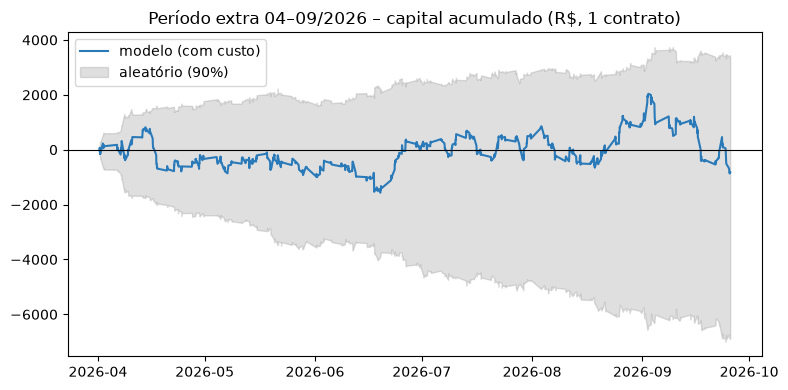

In [4]:
cap = res.cumsum() * rz.REAIS_POR_PONTO["WIN"]
trajs = np.cumsum(rng.choice([-1, 1], size=(200, len(mov))) * mov - rz.CUSTO_PTS, axis=1) * rz.REAIS_POR_PONTO["WIN"]
fig, a = plt.subplots(figsize=(8, 4))
a.plot(cap.index, cap.values, color="#2a7ab9", label="modelo (com custo)")
a.fill_between(cap.index, np.percentile(trajs, 5, axis=0), np.percentile(trajs, 95, axis=0), color="gray", alpha=.25, label="aleatório (90%)")
a.axhline(0, color="k", lw=.8); a.set_title("Período extra 04–09/2026 – capital acumulado (R$, 1 contrato)"); a.legend(loc="upper left")
plt.tight_layout(); plt.savefig("passo07b_curva_capital.png", dpi=120); plt.show()

## Conclusões do Passo 7b

| | Validação 2024 | Teste 01/25–03/26 | **Extra 04–09/26** |
|---|---|---|---|
| Operações | 1.532 | 2.114 | 851 |
| Esperança líquida (pts/op) | +14,1 | +3,0 | **−4,8** |
| Ganho bruto (pts/op) | +19,1 | +8,0 | **+0,2** |
| t | 1,8 | 0,3 | −0,2 |
| p vs aleatório | 0,01 | 0,20 | 0,52 |
| Total (1 contrato) | R$ 4.307 | R$ 1.260 | **−R$ 819** |

1. **No período extra o modelo perdeu**: −4,8 pts/op, praticamente o próprio custo – o ganho bruto foi quase zero (+0,2 pts/op), ou seja, a direção prevista **não teve valor** nesses seis meses.
2. **Um mês pesa muito:** junho a agosto foram bons (+13 a +23 pts/op), mas setembro teve −66 pts/op (−R$ 1.689) e apagou o lucro. Com ~150 operações por mês, a variação mês a mês é enorme.
3. **Somando as duas provas fora da amostra** (teste + extra, 2.965 operações): +2.205 pts, **≈ +0,7 pt líquido por operação** – na prática, empate com o custo.
4. **Conclusão da frente:** o processo melhorou bastante em relação ao modelo anterior (−4,8 → ~0 pts/op fora da amostra) e cada decisão tem justificativa, mas **a RF não encontrou um sinal no WIN forte e estável o bastante para pagar o custo de forma consistente**. O que pareceu vantagem em 2024 foi, em grande parte, específico daquele ano.
